In [15]:
import pandas as pd
import matplotlib.pyplot as plt

In [20]:
Weather = pd.read_csv("weather_forecast_data.csv")

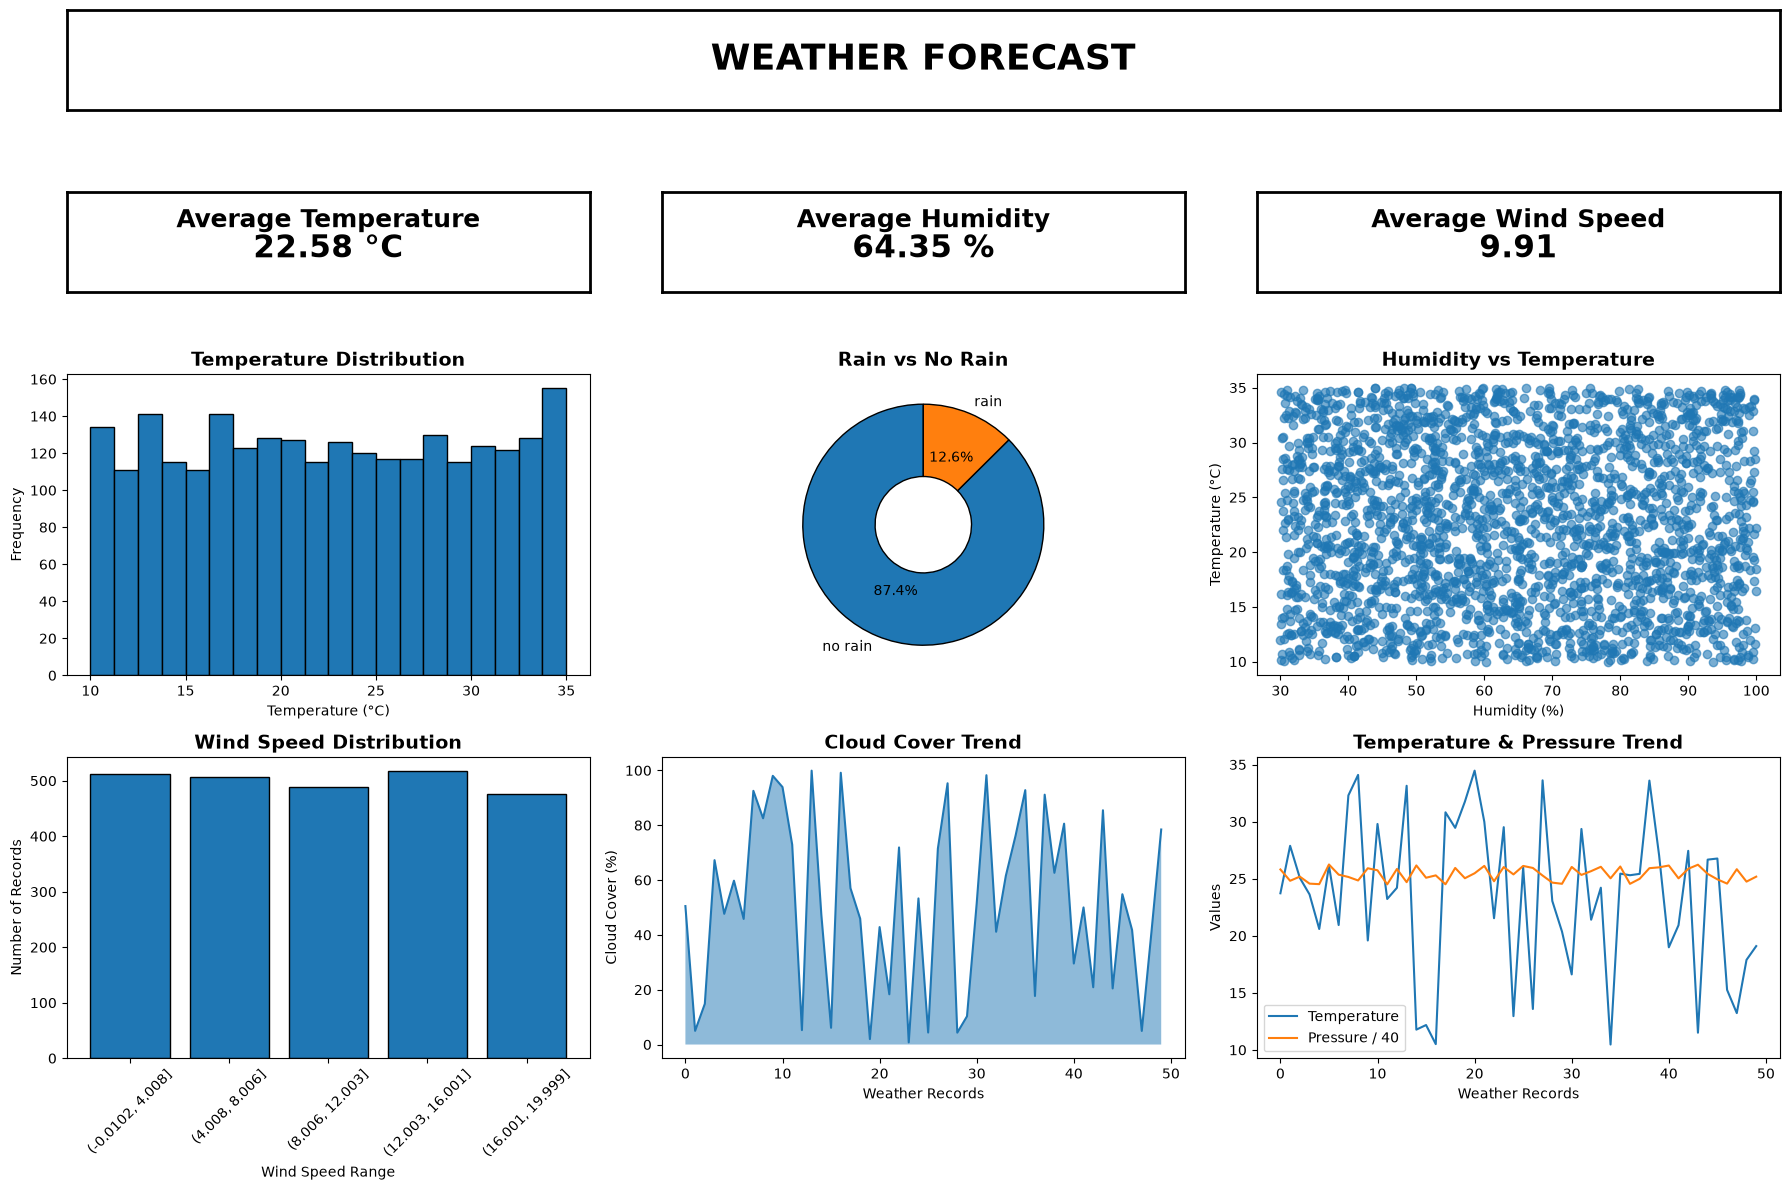

In [28]:
avg_temperature = Weather["Temperature"].mean()

avg_humidity = Weather["Humidity"].mean()

avg_wind_speed = Weather["Wind_Speed"].mean()

rainy_days = (Weather["Rain"].str.lower() == "rain").sum()

fig = plt.figure(figsize=(18, 12))

gs = fig.add_gridspec(
    4,
    3,
    height_ratios=[1, 1, 3, 3]
)

ax_title = fig.add_subplot(gs[0, :])

ax_title.text(
    0.5,
    0.5,
    "WEATHER FORECAST",
    fontsize=26,
    fontweight="bold",
    ha="center",
    va="center"
)

ax_title.set_xticks([])
ax_title.set_yticks([])

for spine in ax_title.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(2)
    
kpi1 = fig.add_subplot(gs[1, 0])
kpi2 = fig.add_subplot(gs[1, 1])
kpi3 = fig.add_subplot(gs[1, 2])


for i in [kpi1, kpi2, kpi3]:

    i.set_xticks([])
    i.set_yticks([])

    for spine in i.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(2)    
 
kpi1.text(
    0.5,
    0.65,
    "Average Temperature",
    ha="center",
    fontsize=18,
    fontweight="bold"
)

kpi1.text(
    0.5,
    0.35,
    f"{avg_temperature:.2f} °C",
    ha="center",
    fontsize=22,
    fontweight="bold"
)

kpi2.text(
    0.5,
    0.65,
    "Average Humidity",
    ha="center",
    fontsize=18,
    fontweight="bold"
)

kpi2.text(
    0.5,
    0.35,
    f"{avg_humidity:.2f} %",
    ha="center",
    fontsize=22,
    fontweight="bold"
)

kpi3.text(
    0.5,
    0.65,
    "Average Wind Speed",
    ha="center",
    fontsize=18,
    fontweight="bold"
)

kpi3.text(
    0.5,
    0.35,
    f"{avg_wind_speed:.2f}",
    ha="center",
    fontsize=22,
    fontweight="bold"
)

ax1 = fig.add_subplot(gs[2, 0])

ax1.hist(
    Weather["Temperature"],
    bins=20,
    edgecolor="black"
)

ax1.set_title(
    "Temperature Distribution",
    fontsize=14,
    fontweight="bold"
)

ax1.set_xlabel("Temperature (°C)")
ax1.set_ylabel("Frequency")

ax2 = fig.add_subplot(gs[2, 1])

rain_count = Weather["Rain"].value_counts()

ax2.pie(
    rain_count.values,
    labels=rain_count.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={
        "edgecolor": "black",
        "width": 0.6
    }
)

ax2.set_title(
    "Rain vs No Rain",
    fontsize=14,
    fontweight="bold"
)

ax3 = fig.add_subplot(gs[2, 2])

ax3.scatter(
    Weather["Humidity"],
    Weather["Temperature"],
    alpha=0.6
)

ax3.set_title(
    "Humidity vs Temperature",
    fontsize=14,
    fontweight="bold"
)

ax3.set_xlabel("Humidity (%)")
ax3.set_ylabel("Temperature (°C)")

ax4 = fig.add_subplot(gs[3, 0])

wind_bins = pd.cut(
    Weather["Wind_Speed"],
    bins=5
)

wind_data = Weather.groupby(
    wind_bins,
    observed=False
)["Wind_Speed"].count()

ax4.bar(
    wind_data.index.astype(str),
    wind_data.values,
    edgecolor="black"
)

ax4.set_title(
    "Wind Speed Distribution",
    fontsize=14,
    fontweight="bold"
)

ax4.set_xlabel("Wind Speed Range")
ax4.set_ylabel("Number of Records")

ax4.tick_params(
    axis="x",
    rotation=45
)

ax5 = fig.add_subplot(gs[3, 1])

cloud_data = Weather["Cloud_Cover"].head(50)

ax5.fill_between(
    range(len(cloud_data)),
    cloud_data.values,
    alpha=0.5
)

ax5.plot(
    range(len(cloud_data)),
    cloud_data.values
)

ax5.set_title(
    "Cloud Cover Trend",
    fontsize=14,
    fontweight="bold"
)

ax5.set_xlabel("Weather Records")
ax5.set_ylabel("Cloud Cover (%)")

ax6 = fig.add_subplot(gs[3, 2])

pressure_data = Weather.head(50)

ax6.plot(
    pressure_data["Temperature"].values,
    label="Temperature"
)

ax6.plot(
    pressure_data["Pressure"].values / 40,
    label="Pressure / 40"
)

ax6.set_title(
    "Temperature & Pressure Trend",
    fontsize=14,
    fontweight="bold"
)

ax6.set_xlabel("Weather Records")
ax6.set_ylabel("Values")

ax6.legend()

plt.tight_layout()

plt.show()

In [29]:
Weather["Rain"] = Weather["Rain"].astype(str).str.strip()

C:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 127777 (\N{THERMOMETER}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128167 (\N{DROPLET}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128168 (\N{DASH SYMBOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 127783 (\N{CLOUD WITH RAIN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


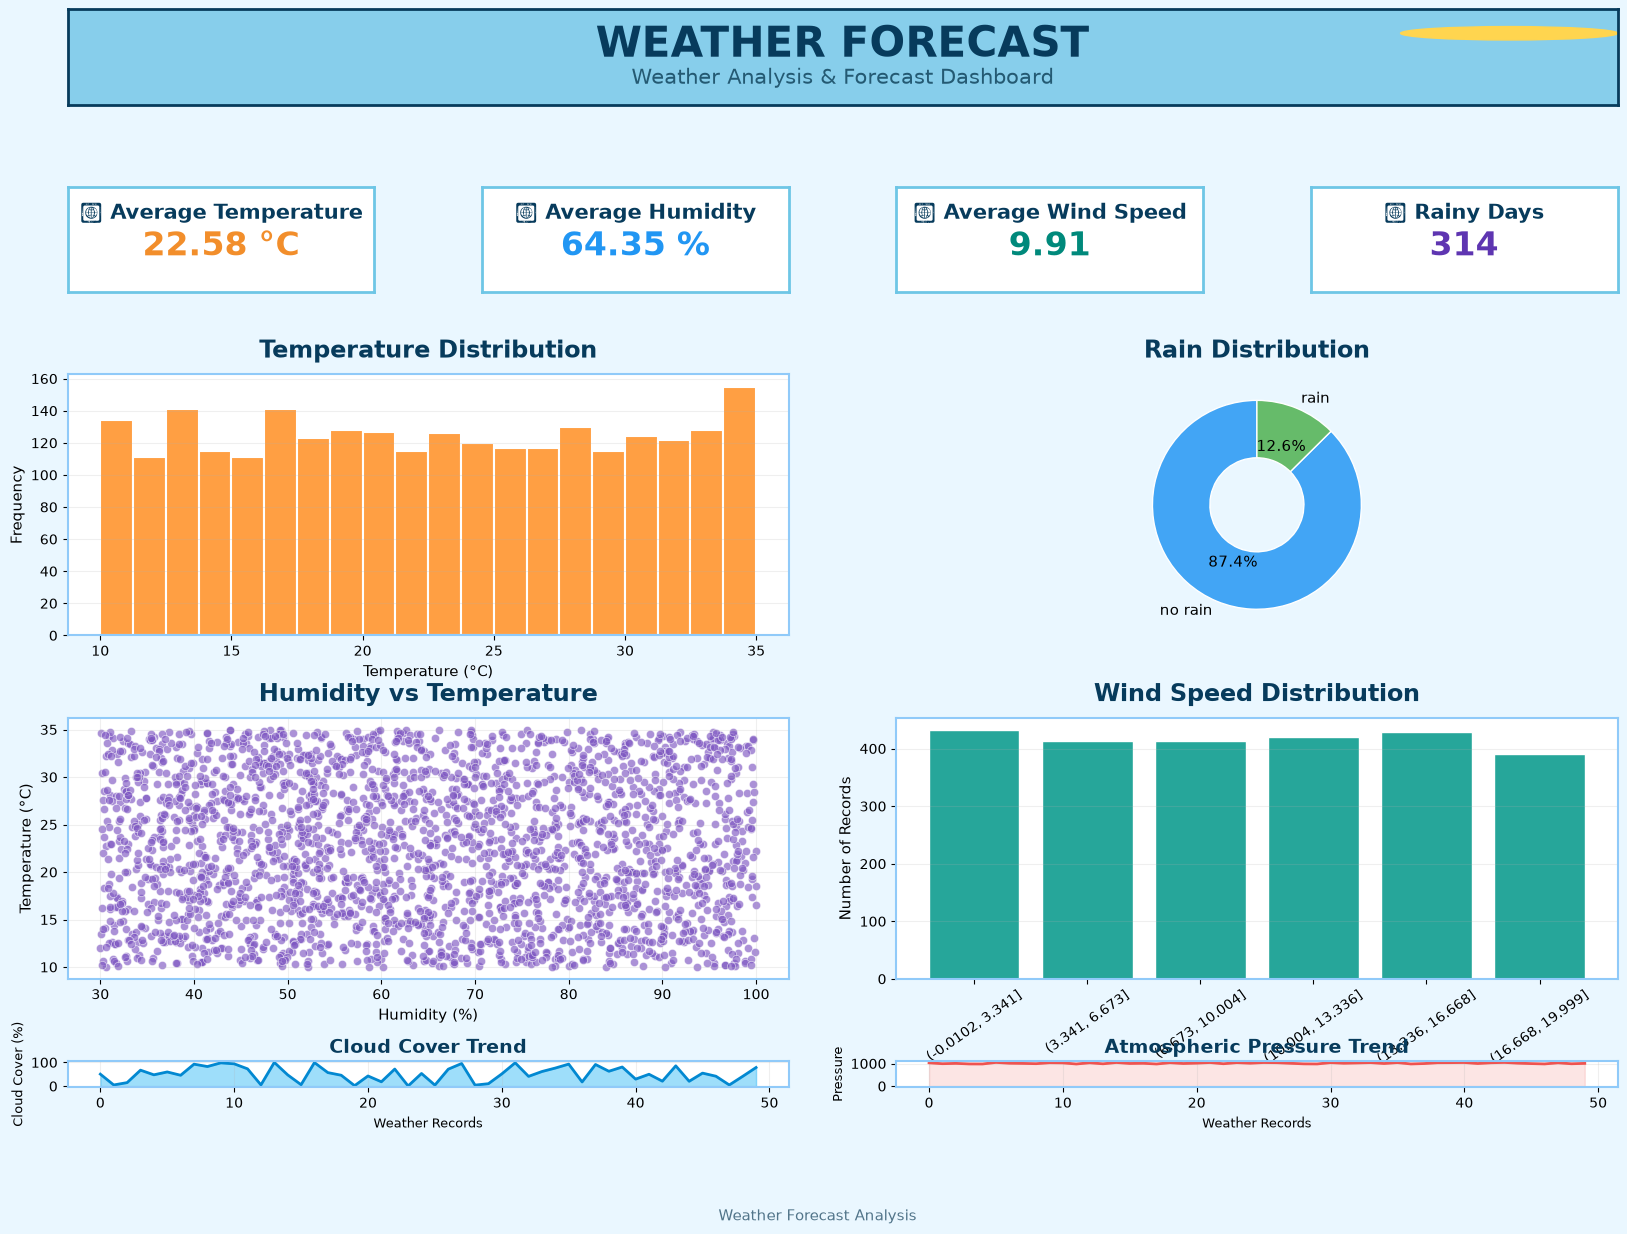

In [31]:
numeric_columns = [
    "Temperature",
    "Humidity",
    "Wind_Speed",
    "Cloud_Cover",
    "Pressure"
]

for col in numeric_columns:
    Weather[col] = pd.to_numeric(Weather[col], errors="coerce")
    
avg_temperature = Weather["Temperature"].mean()

avg_humidity = Weather["Humidity"].mean()

avg_wind_speed = Weather["Wind_Speed"].mean()

rainy_days = (
    Weather["Rain"].str.lower() == "rain"
).sum()

fig = plt.figure(
    figsize=(20, 14),
    facecolor="#EAF7FF"
)

gs = fig.add_gridspec(
    5,
    4,
    height_ratios=[1.1, 1.2, 3, 3, 0.3],
    hspace=0.55,
    wspace=0.35
)

ax_title = fig.add_subplot(gs[0, :])

ax_title.set_facecolor("#87CEEB")

ax_title.text(
    0.5,
    0.62,
    "WEATHER FORECAST",
    fontsize=30,
    fontweight="bold",
    ha="center",
    va="center",
    color="#073B5C"
)

ax_title.text(
    0.5,
    0.28,
    "Weather Analysis & Forecast Dashboard",
    fontsize=15,
    ha="center",
    va="center",
    color="#245A73"
)

ax_title.set_xticks([])
ax_title.set_yticks([])

for spine in ax_title.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(2)
    spine.set_edgecolor("#073B5C")
    
sun = plt.Circle(
    (0.93, 0.75),
    0.07,
    transform=ax_title.transAxes,
    color="#FFD54F"
)

ax_title.add_patch(sun)

kpi1 = fig.add_subplot(gs[1, 0])

kpi2 = fig.add_subplot(gs[1, 1])

kpi3 = fig.add_subplot(gs[1, 2])

kpi4 = fig.add_subplot(gs[1, 3])


kpis = [kpi1, kpi2, kpi3, kpi4]

for ax in kpis:

    ax.set_facecolor("white")

    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():

        spine.set_visible(True)
        spine.set_linewidth(2)
        spine.set_edgecolor("#6EC6E6")
        
kpi1.text(
    0.5,
    0.70,
    "🌡 Average Temperature",
    ha="center",
    fontsize=15,
    fontweight="bold",
    color="#073B5C"
)

kpi1.text(
    0.5,
    0.35,
    f"{avg_temperature:.2f} °C",
    ha="center",
    fontsize=24,
    fontweight="bold",
    color="#F28E2B"
)

kpi2.text(
    0.5,
    0.70,
    "💧 Average Humidity",
    ha="center",
    fontsize=15,
    fontweight="bold",
    color="#073B5C"
)

kpi2.text(
    0.5,
    0.35,
    f"{avg_humidity:.2f} %",
    ha="center",
    fontsize=24,
    fontweight="bold",
    color="#2196F3"
)

kpi3.text(
    0.5,
    0.70,
    "💨 Average Wind Speed",
    ha="center",
    fontsize=15,
    fontweight="bold",
    color="#073B5C"
)

kpi3.text(
    0.5,
    0.35,
    f"{avg_wind_speed:.2f}",
    ha="center",
    fontsize=24,
    fontweight="bold",
    color="#00897B"
)

kpi4.text(
    0.5,
    0.70,
    "🌧 Rainy Days",
    ha="center",
    fontsize=15,
    fontweight="bold",
    color="#073B5C"
)

kpi4.text(
    0.5,
    0.35,
    f"{rainy_days}",
    ha="center",
    fontsize=24,
    fontweight="bold",
    color="#5E35B1"
)

ax1 = fig.add_subplot(gs[2, 0:2])

ax1.set_facecolor("white")

ax1.hist(
    Weather["Temperature"].dropna(),
    bins=20,
    color="#FF9F43",
    edgecolor="white",
    linewidth=1.5
)

ax1.set_title(
    "Temperature Distribution",
    fontsize=17,
    fontweight="bold",
    color="#073B5C",
    pad=12
)

ax1.set_xlabel(
    "Temperature (°C)",
    fontsize=11
)

ax1.set_ylabel(
    "Frequency",
    fontsize=11
)

ax1.grid(
    axis="y",
    alpha=0.2
)

ax2 = fig.add_subplot(gs[2, 2:4])

ax2.set_facecolor("white")

rain_count = Weather["Rain"].value_counts()

ax2.pie(
    rain_count.values,
    labels=rain_count.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=[
        "#42A5F5",
        "#66BB6A",
        "#FFA726",
        "#AB47BC"
    ],
    wedgeprops={
        "edgecolor": "white",
        "width": 0.55
    },
    textprops={
        "fontsize": 11
    }
)

ax2.set_title(
    "Rain Distribution",
    fontsize=17,
    fontweight="bold",
    color="#073B5C",
    pad=12
)

ax3 = fig.add_subplot(gs[3, 0:2])

ax3.set_facecolor("white")

ax3.scatter(
    Weather["Humidity"],
    Weather["Temperature"],
    s=35,
    alpha=0.65,
    color="#7E57C2",
    edgecolors="white",
    linewidth=0.5
)

ax3.set_title(
    "Humidity vs Temperature",
    fontsize=17,
    fontweight="bold",
    color="#073B5C",
    pad=12
)

ax3.set_xlabel(
    "Humidity (%)",
    fontsize=11
)

ax3.set_ylabel(
    "Temperature (°C)",
    fontsize=11
)

ax3.grid(
    alpha=0.2
)

ax4 = fig.add_subplot(gs[3, 2:4])

ax4.set_facecolor("white")

wind_bins = pd.cut(
    Weather["Wind_Speed"],
    bins=6
)

wind_data = (
    Weather
    .groupby(
        wind_bins,
        observed=False
    )
    .size()
)

bars = ax4.bar(
    wind_data.index.astype(str),
    wind_data.values,
    color="#26A69A",
    edgecolor="white"
)

ax4.set_title(
    "Wind Speed Distribution",
    fontsize=17,
    fontweight="bold",
    color="#073B5C",
    pad=12
)

ax4.set_xlabel(
    "Wind Speed Range",
    fontsize=11
)

ax4.set_ylabel(
    "Number of Records",
    fontsize=11
)

ax4.tick_params(
    axis="x",
    rotation=35
)

ax4.grid(
    axis="y",
    alpha=0.2
)

ax5 = fig.add_subplot(gs[4, 0:2])

ax5.set_facecolor("white")

cloud_data = Weather["Cloud_Cover"].head(50)

x_values = np.arange(
    len(cloud_data)
)

ax5.fill_between(
    x_values,
    cloud_data.values,
    alpha=0.45,
    color="#29B6F6"
)

ax5.plot(
    x_values,
    cloud_data.values,
    color="#0288D1",
    linewidth=2
)

ax5.set_title(
    "Cloud Cover Trend",
    fontsize=14,
    fontweight="bold",
    color="#073B5C"
)

ax5.set_xlabel(
    "Weather Records",
    fontsize=9
)

ax5.set_ylabel(
    "Cloud Cover (%)",
    fontsize=9
)

ax5.grid(
    alpha=0.2
)

ax6 = fig.add_subplot(gs[4, 2:4])

ax6.set_facecolor("white")

pressure_data = Weather["Pressure"].head(50)

ax6.plot(
    pressure_data.values,
    color="#EF5350",
    linewidth=2
)

ax6.fill_between(
    range(len(pressure_data)),
    pressure_data.values,
    alpha=0.15,
    color="#EF5350"
)

ax6.set_title(
    "Atmospheric Pressure Trend",
    fontsize=14,
    fontweight="bold",
    color="#073B5C"
)

ax6.set_xlabel(
    "Weather Records",
    fontsize=9
)

ax6.set_ylabel(
    "Pressure",
    fontsize=9
)

ax6.grid(
    alpha=0.2
)

charts = [
    ax1,
    ax2,
    ax3,
    ax4,
    ax5,
    ax6
]

for ax in charts:

    for spine in ax.spines.values():

        spine.set_visible(True)
        spine.set_linewidth(1.5)
        spine.set_edgecolor("#90CAF9")
        
fig.text(
    0.5,
    0.015,
    "Weather Forecast Analysis",
    ha="center",
    fontsize=11,
    color="#52758A"
)

plt.show()